# Дополнительное задание к лабораторной работе №3
## Глубокая кластеризация VaDE

Это отдельное дополнительное задание. Основной отчёт не менялся и лежит в корне репозитория: `lab3_clustering.ipynb`.

Где смотреть результат:

- ноутбук задания: `dop_zadanie/dop_zadanie.ipynb`
- скрины графиков и таблиц: `dop_zadanie/screenshots/`
- числовые таблицы и текст вывода: `dop_zadanie/output/`

**Цель.** Пройти весь пайплайн глубокой кластеризации: подготовка данных, выбор архитектуры, обучение, подбор гиперпараметров, сравнение с классическими методами и интерпретация групп.

**Данные.** Тот же открытый набор White Wine Quality, файл `data/winequality-white.csv`. Одна строка — один образец белого вина. В признаки идёт химический анализ. Оценка `quality` в обучение не подаётся и нужна только как внешняя проверка.

**Метод.** В основной лабораторной уже сделан DEC (автокодировщик и K-means). Здесь взят другой метод из списка задания: **VaDE**, вариационный автокодировщик со смесью гауссиан в латентном пространстве (Jiang, Zheng, Tian, Tang, 2017).


In [1]:
from pathlib import Path
import os
import time

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import Markdown, display
from itertools import combinations
from sklearn.cluster import DBSCAN, KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    completeness_score,
    davies_bouldin_score,
    homogeneity_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

PROJECT = Path.cwd().resolve()
if not (PROJECT / "data" / "winequality-white.csv").exists():
    PROJECT = PROJECT.parent
DATA_PATH = PROJECT / "data" / "winequality-white.csv"
DOP = PROJECT / "dop_zadanie"
SHOTS = DOP / "screenshots"
OUT = DOP / "output"
SHOTS.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TARGET = "quality"
CORR_LIMIT = 0.80
MIN_CLUSTER_SHARE = 0.05
GRID_PRE_EPOCHS = 6
GRID_VADE_EPOCHS = 5
FINAL_PRE_EPOCHS = 18
FINAL_VADE_EPOCHS = 12
LATENT_GRID = (2, 4, 8)
CLUSTER_GRID = (2, 3, 4)
LR_GRID = (0.001, 0.005)
L2_GRID = (0.0, 1e-4)

FEATURES = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
]
LABELS = {
    "fixed acidity": "Фиксированная кислотность",
    "volatile acidity": "Летучая кислотность",
    "citric acid": "Лимонная кислота",
    "residual sugar": "Остаточный сахар",
    "chlorides": "Хлориды",
    "free sulfur dioxide": "Свободный диоксид серы",
    "total sulfur dioxide": "Общий диоксид серы",
    "density": "Плотность",
    "pH": "pH",
    "sulphates": "Сульфаты",
    "alcohol": "Спирт",
    "quality": "Оценка",
}

tf.keras.utils.set_random_seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 140

def save_fig(fig, name):
    path = SHOTS / name
    fig.savefig(path, bbox_inches="tight")
    print("скрин:", path.relative_to(PROJECT).as_posix())

def num(value, digits=3):
    text = f"{float(value):.{digits}f}".rstrip("0").rstrip(".")
    if text in {"", "-0"}:
        text = "0"
    return text.replace(".", ",")

print("Проект:", PROJECT)
print("Ноутбук доп. задания: dop_zadanie/dop_zadanie.ipynb")
print("Скрины:", SHOTS.relative_to(PROJECT).as_posix())
print("Таблицы:", OUT.relative_to(PROJECT).as_posix())


Проект: C:\Users\l-dan\Desktop\MO_3lab
Ноутбук доп. задания: dop_zadanie/dop_zadanie.ipynb
Скрины: dop_zadanie/screenshots
Таблицы: dop_zadanie/output


## 1. Загрузка и первичный анализ

Смотрим размер таблицы, типы, пропуски, хвосты и форму распределений. Оценка качества отделена от признаков сразу: иначе кластеризация увидит готовый ответ.


,тип,пропуски,среднее,СКО,мин,макс,асимметрия
Фиксированная кислотность,float64,0,6.855,0.844,3.800,14.200,0.648
Летучая кислотность,float64,0,0.278,0.101,0.080,1.100,1.577
Лимонная кислота,float64,0,0.334,0.121,0.000,1.660,1.282
Остаточный сахар,float64,0,6.391,5.072,0.600,65.800,1.077
Хлориды,float64,0,0.046,0.022,0.009,0.346,5.023
Свободный диоксид серы,float64,0,35.308,17.007,2.000,289.000,1.407
Общий диоксид серы,float64,0,138.361,42.498,9.000,440.000,0.391
Плотность,float64,0,0.994,0.003,0.987,1.039,0.978
pH,float64,0,3.188,0.151,2.720,3.820,0.458
Сульфаты,float64,0,0.490,0.114,0.220,1.080,0.977


скрин: dop_zadanie/screenshots/01_opisanie_priznakov.png


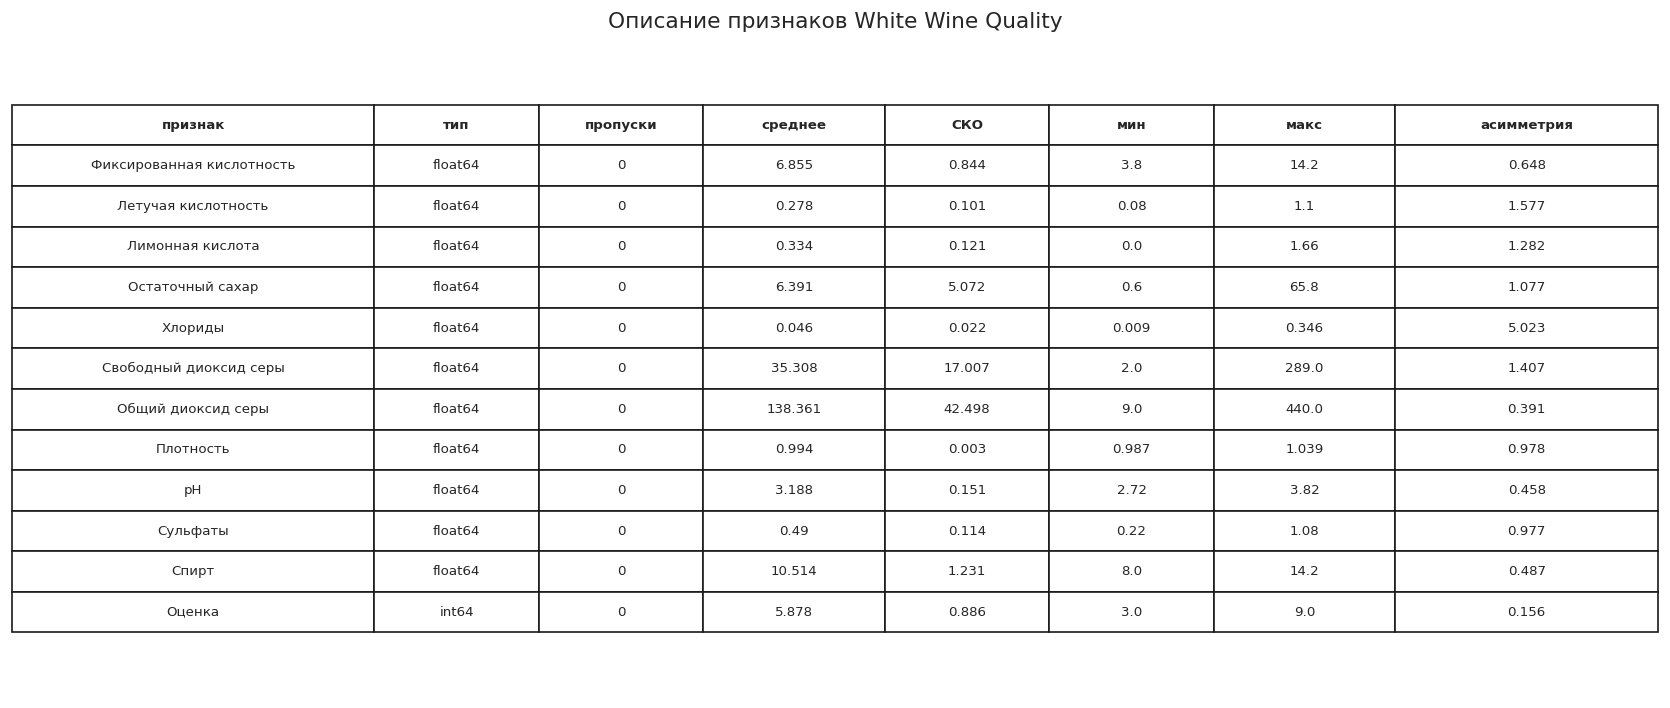

Наблюдений: 4898
Столбцов: 12
Пропусков всего: 0
Категориальных столбцов нет: все измерения числовые, оценка тоже число.
Оценки: {3: 20, 4: 163, 5: 1457, 6: 2198, 7: 880, 8: 175, 9: 5}
Строк с хотя бы одним хвостом по правилу 1,5 IQR: 883
Хвосты по признакам: {'Лимонная кислота': 270, 'Хлориды': 208, 'Летучая кислотность': 186, 'Сульфаты': 124}
Самая сильная асимметрия:


,асимметрия
Хлориды,5.02
Летучая кислотность,1.58
Свободный диоксид серы,1.41
Лимонная кислота,1.28


скрин: dop_zadanie/screenshots/02_raspredeleniya.png


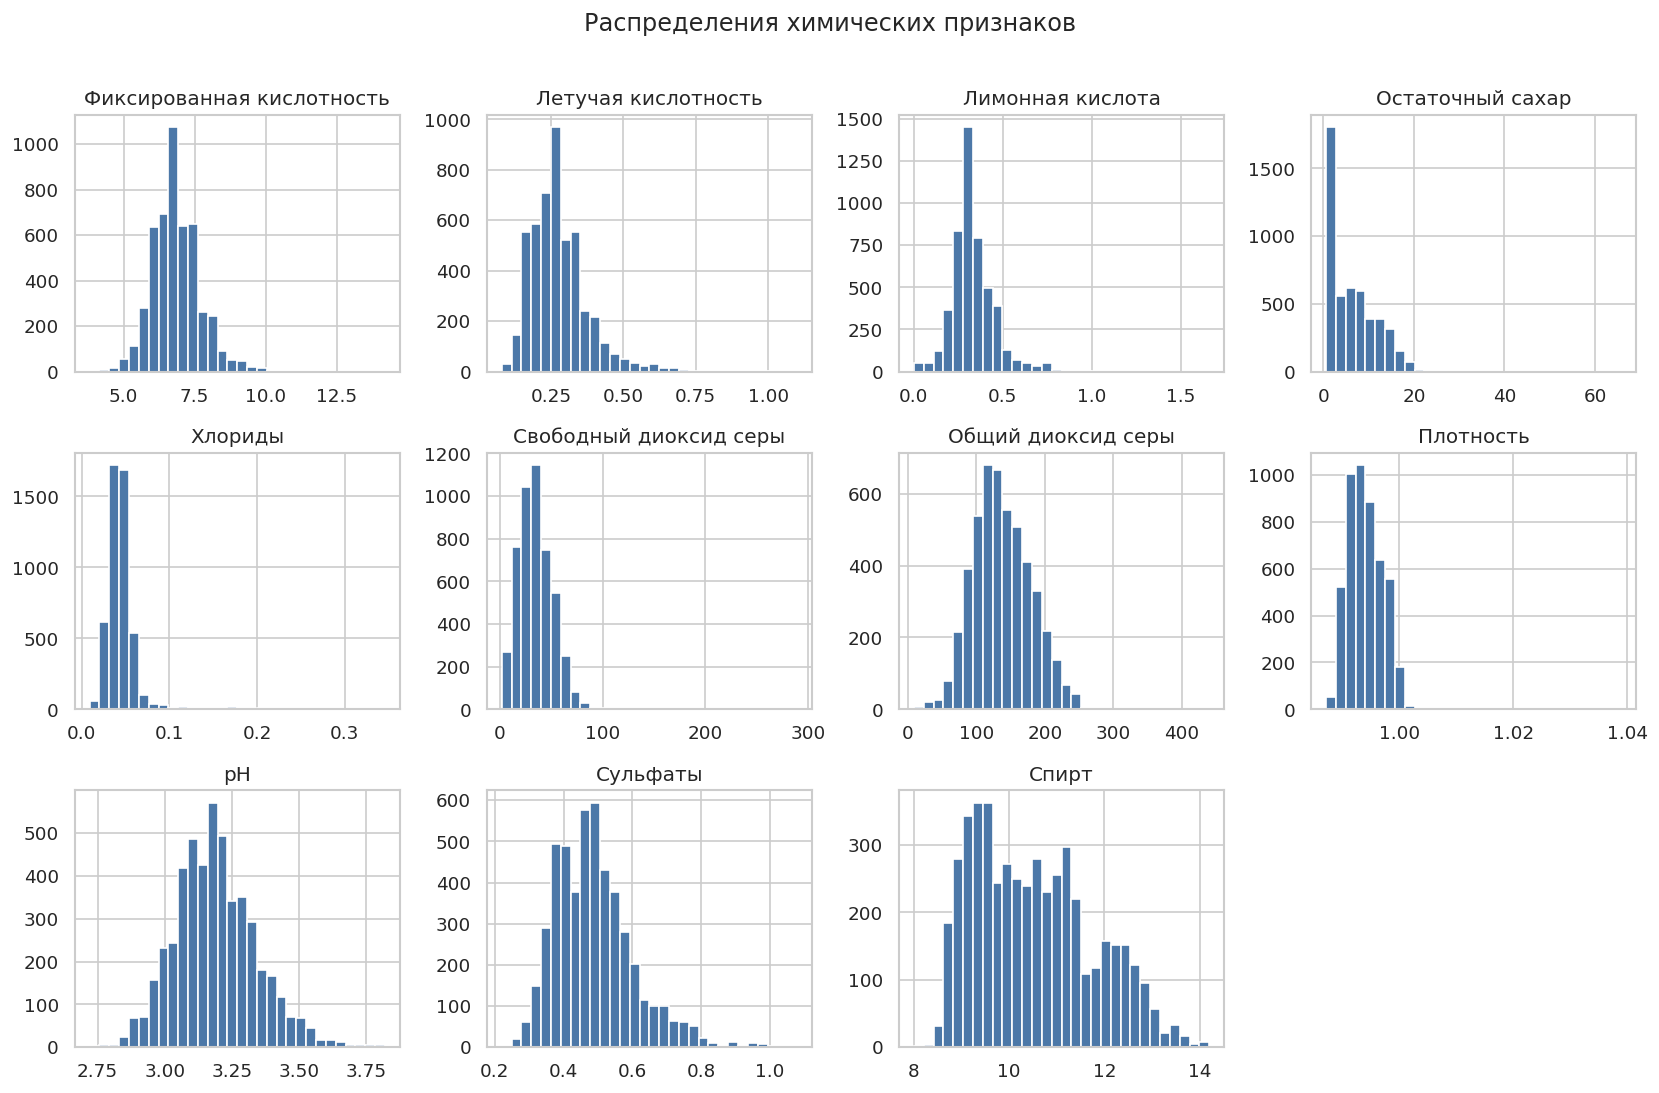

In [2]:
raw = pd.read_csv(DATA_PATH, sep=";").reset_index(drop=True)
y = raw[TARGET].to_numpy()

summary = pd.DataFrame({
    "тип": raw.dtypes.astype(str),
    "пропуски": raw.isna().sum(),
    "среднее": raw.mean(numeric_only=True),
    "СКО": raw.std(numeric_only=True),
    "мин": raw.min(numeric_only=True),
    "макс": raw.max(numeric_only=True),
    "асимметрия": raw.skew(numeric_only=True),
})
summary.index = [LABELS.get(name, name) for name in summary.index]
summary.to_csv(OUT / "description.csv", encoding="utf-8-sig")
display(summary.round(3))

fig, ax = plt.subplots(figsize=(14, 6.2))
ax.axis("off")
ax.set_title("Описание признаков White Wine Quality", pad=8, fontsize=13)
shown = summary.round(3).reset_index().rename(columns={"index": "признак"})
shown = shown.astype(str)
table = ax.table(cellText=shown.values, colLabels=shown.columns, loc="center", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(8)
widths = [0.22, 0.10, 0.10, 0.11, 0.10, 0.10, 0.11, 0.16]
for (row_id, col_id), cell in table.get_celld().items():
    cell.set_width(widths[col_id])
    cell.set_height(0.062)
    if row_id == 0:
        cell.set_text_props(weight="bold")
fig.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.02)
save_fig(fig, "01_opisanie_priznakov.png")
plt.show()

print(f"Наблюдений: {len(raw)}")
print(f"Столбцов: {raw.shape[1]}")
print(f"Пропусков всего: {int(raw.isna().sum().sum())}")
print("Категориальных столбцов нет: все измерения числовые, оценка тоже число.")
print("Оценки:", dict(sorted(raw[TARGET].value_counts().to_dict().items())))

outlier = pd.Series(False, index=raw.index)
outlier_counts = {}
for feature in FEATURES:
    q1, q3 = raw[feature].quantile([0.25, 0.75])
    fence = 1.5 * (q3 - q1)
    mask = (raw[feature] < q1 - fence) | (raw[feature] > q3 + fence)
    outlier_counts[LABELS[feature]] = int(mask.sum())
    outlier |= mask
print(f"Строк с хотя бы одним хвостом по правилу 1,5 IQR: {int(outlier.sum())}")
print("Хвосты по признакам:", dict(sorted(outlier_counts.items(), key=lambda item: -item[1])[:4]))

skewed = summary["асимметрия"].abs().sort_values(ascending=False)
print("Самая сильная асимметрия:")
display(skewed.head(4).round(2).to_frame("асимметрия"))

fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for axis, feature in zip(axes.ravel(), FEATURES):
    axis.hist(raw[feature], bins=30, color="#4C78A8", edgecolor="white")
    axis.set_title(LABELS[feature])
axes.ravel()[-1].axis("off")
fig.suptitle("Распределения химических признаков", y=1.01)
fig.tight_layout()
save_fig(fig, "02_raspredeleniya.png")
plt.show()


### Пригодность данных для кластеризации

Таблица небольшая и чистая: 4898 строк, 11 числовых признаков, пропусков нет. Кодировать категории не нужно. Заполнять пропуски тоже не нужно: если бы пустые ячейки были, числовые дыры закрывались бы медианой, чтобы один редкий хвост не утащил среднее.

К нормальному колоколу распределения не близки. Длинные правые хвосты есть у хлоридов, сахара и диоксида серы. По правилу полутора межквартильных размахов такие строки есть, но это редкие настоящие составы, а не сбой записи, поэтому выборку не режем.

Семь баллов качества не выглядят семью отдельными химическими кучами: на гистограммах признаки одномодны или с одним длинным хвостом, а крайние оценки 3 и 9 почти пустые. Разумный перебор числа групп — от 2 до 4. Ниже по плоскости сахара и спирта это будет видно напрямую. Размерность низкая, шум умеренный: глубокая модель здесь не обязана выиграть у K-means и EM, и как раз это нужно проверить.


## 2. Предобработка

Признаки живут в разных единицах: диоксид серы измеряется десятками, плотность около единицы, спирт около десяти. Без масштаба расстояние почти целиком определяется серой. Берём `StandardScaler`.

Плотность физически повторяет сахар и спирт. Если модуль корреляции выше 0,80, плотность убираем, а сахар и спирт оставляем: это исходные измерения, а не пересказ.


скрин: dop_zadanie/screenshots/03_korrelyaciya.png


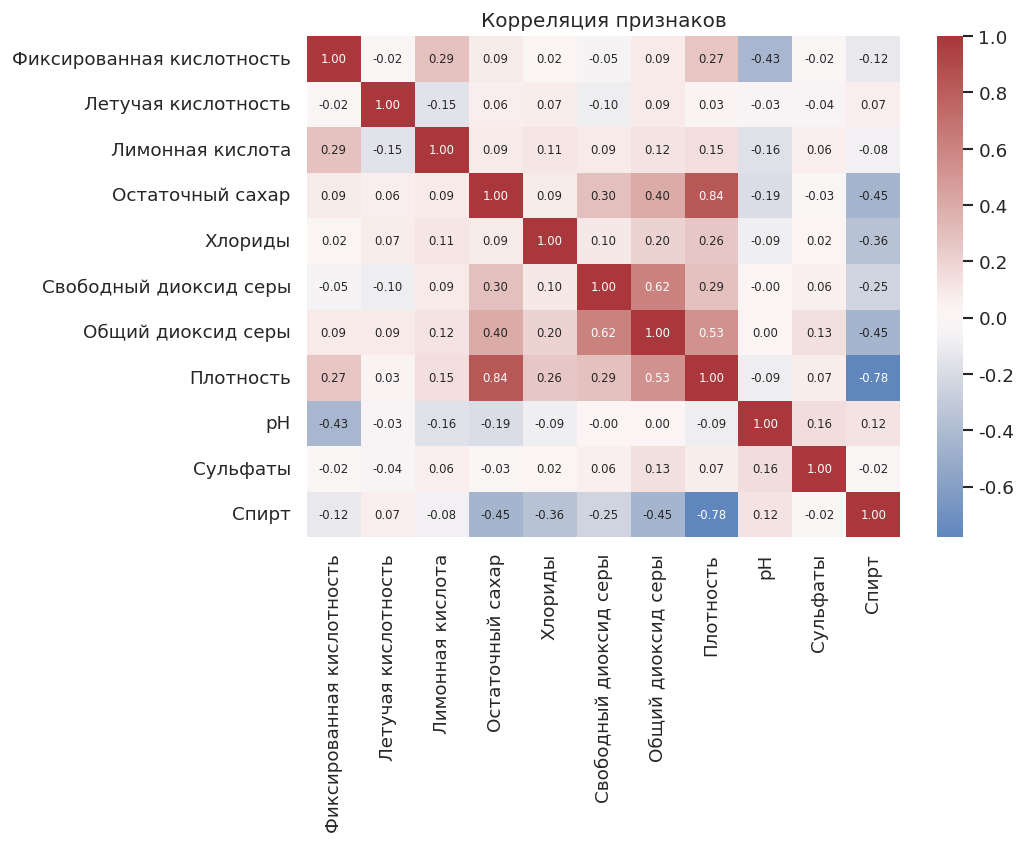

Пары с |r| > 0,80: [('Остаточный сахар', 'Плотность', 0.8389664549045714)]
Убранные признаки: ['Плотность']
В модели остаются: ['Фиксированная кислотность', 'Летучая кислотность', 'Лимонная кислота', 'Остаточный сахар', 'Хлориды', 'Свободный диоксид серы', 'Общий диоксид серы', 'pH', 'Сульфаты', 'Спирт']
Матрица после масштаба: (4898, 10) среднее -0.0 СКО 1.0


скрин: dop_zadanie/screenshots/04_sahar_i_spirt.png


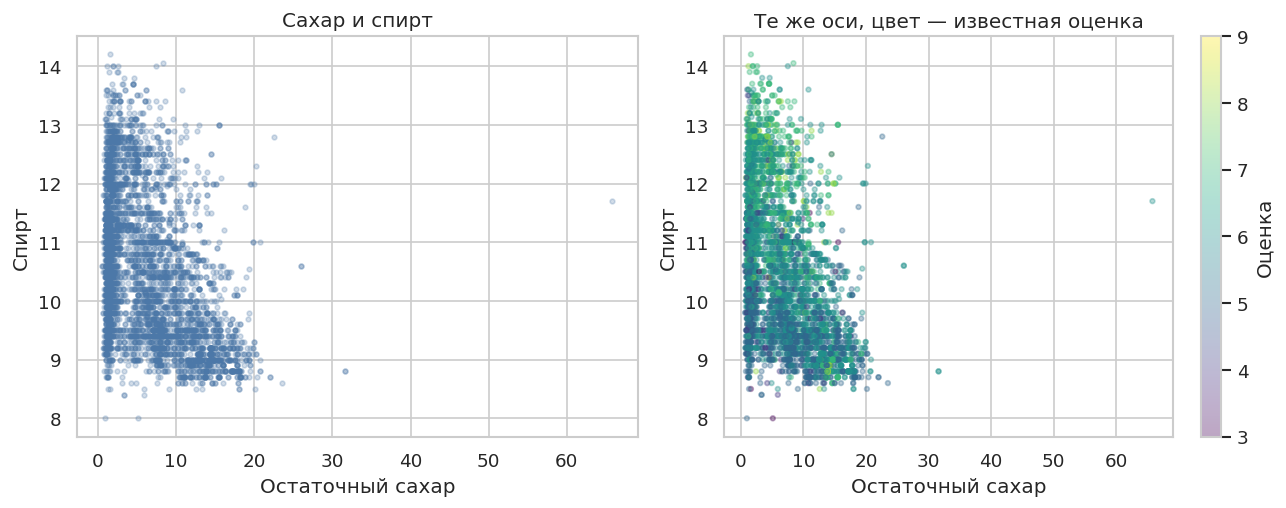

In [3]:
corr = raw[FEATURES].corr()
corr.to_csv(OUT / "correlation.csv", encoding="utf-8-sig")
corr_show = corr.rename(index=LABELS, columns=LABELS)

fig, ax = plt.subplots(figsize=(9, 7.2))
sns.heatmap(corr_show, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, annot_kws={"size": 7})
ax.set_title("Корреляция признаков")
fig.tight_layout()
save_fig(fig, "03_korrelyaciya.png")
plt.show()

pairs = []
for i, left in enumerate(FEATURES):
    for right in FEATURES[i + 1:]:
        value = float(corr.loc[left, right])
        if abs(value) > CORR_LIMIT:
            pairs.append((LABELS[left], LABELS[right], value))
print("Пары с |r| > 0,80:", pairs if pairs else "нет")

dropped = ["density"]
kept = [feature for feature in FEATURES if feature not in dropped]
print("Убранные признаки:", [LABELS[feature] for feature in dropped])
print("В модели остаются:", [LABELS[feature] for feature in kept])

scaler = StandardScaler()
x_scaled = scaler.fit_transform(raw[kept].to_numpy(dtype=np.float32)).astype(np.float32)
print("Матрица после масштаба:", x_scaled.shape, "среднее", round(float(x_scaled.mean()), 4), "СКО", round(float(x_scaled.std()), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].scatter(raw["residual sugar"], raw["alcohol"], s=8, alpha=0.25, c="#4C78A8")
axes[0].set_title("Сахар и спирт")
axes[0].set_xlabel(LABELS["residual sugar"])
axes[0].set_ylabel(LABELS["alcohol"])
scatter = axes[1].scatter(
    raw["residual sugar"], raw["alcohol"], s=8, alpha=0.35, c=y, cmap="viridis"
)
axes[1].set_title("Те же оси, цвет — известная оценка")
axes[1].set_xlabel(LABELS["residual sugar"])
axes[1].set_ylabel(LABELS["alcohol"])
fig.colorbar(scatter, ax=axes[1], label=LABELS["quality"])
fig.tight_layout()
save_fig(fig, "04_sahar_i_spirt.png")
plt.show()


### Вывод по подготовке

Пропусков не было, категорий не было, масштаб выровнен, плотность убрана как дубль сахара. На плоскости сахар–спирт облако вытянутое и непрерывное, а цвета оценок внутри него перемешаны. Значит, кластеры, если они есть, — это химические стили, а не семь дегустационных баллов. В таком виде данные для кластеризации пригодны.


## 3. Выбор метода и архитектура

**Почему VaDE, а не повтор DEC.** DEC уже разобран в `lab3_clustering.ipynb`: там автокодировщик и расстояние до центров. VaDE отвечает на другой вопрос. Латентный вектор считается случайным, априори он приходит из смеси гауссиан, и номер компоненты этой смеси и есть кластер. Компоненты могут быть эллипсами, а не одинаковыми шарами.

**Почему не SOM.** Карта Кохонена тоже есть в списке задания, но она не даёт вероятности кластера и функции правдоподобия. Для сравнения с EM-алгоритмом удобнее модель, у которой классический родственник — та же смесь гауссиан.

**Сеть.** Кодировщик: 10 → 64 → 32 → латентный слой. Из последнего скрытого слоя выходят два линейных вектора: среднее и логарифм дисперсии. Декодер симметричный: латентный вектор → 32 → 64 → 10. Скрытые слои с ReLU. Латентный слой и выход линейные: после стандартизации признаки бывают отрицательными, ReLU на выходе обрезал бы половину значений.

**Что обучается вместе.** Сначала вариационный автокодировщик учится восстанавливать вектор и держать апостериорное распределение близко к стандартному нормальному. Потом по латентным средним запускается GMM, и его веса, центры и диагональные дисперсии становятся стартом смеси. Дальше кодировщик, декодер и параметры смеси обновляются одним оптимизатором Adam.

**Функция потерь.** На одном образце складываются четыре части:

1. половина суммы квадратов ошибки восстановления — гауссовский декодер с фиксированной дисперсией;
2. квадратичная часть KL между гауссианой кодера и компонентами смеси;
3. энтропийная часть того же KL, через логарифм дисперсии кодера;
4. расхождение мягких назначений γ с весами смеси π.

Номер кластера — аргумент максимума γ. γ считается по среднему латентного распределения, чтобы метка не дрожала от одной случайной выборки. Сам восстановительный проход во время обучения идёт через репараметризацию: z = μ + σ ε.

**Регуляризация.** Штраф λ на сумму квадратов весов кодировщика и декодера. Смесь этим штрафом не трогаем: у неё мало параметров, их как раз нужно двигать. Dropout не добавляем, чтобы не заводить второй, незапланированный коэффициент. Ковариация компонент диагональная: наблюдений несколько тысяч, а в основной работе полная матрица GMM силуэт не улучшила.

**Как выбираем настройку.** Перебираем латентную размерность, число кластеров, скорость обучения и λ. В сетке обучение короткое и нужно только для сравнения. Критерий — силуэт в исходном стандартизованном пространстве. Оценка качества в критерий не входит. Конфигурация отбрасывается, если какой-то кластер меньше 5% выборки: иначе силуэт можно набрать одним крошечным хвостом. Победителя потом обучаем дольше.


In [4]:
class VaDE(tf.keras.Model):
    def __init__(self, input_dim, latent_dim, n_clusters):
        super().__init__()
        self.latent_dim = latent_dim
        self.n_clusters = n_clusters
        self.enc1 = tf.keras.layers.Dense(64, activation="relu")
        self.enc2 = tf.keras.layers.Dense(32, activation="relu")
        self.mu_layer = tf.keras.layers.Dense(latent_dim)
        self.logvar_layer = tf.keras.layers.Dense(latent_dim)
        self.dec1 = tf.keras.layers.Dense(32, activation="relu")
        self.dec2 = tf.keras.layers.Dense(64, activation="relu")
        self.out_layer = tf.keras.layers.Dense(input_dim)
        self.gmm_logits = tf.Variable(tf.zeros([n_clusters]), name="gmm_logits")
        self.gmm_mu = tf.Variable(tf.zeros([n_clusters, latent_dim]), name="gmm_mu")
        self.gmm_logvar = tf.Variable(tf.fill([n_clusters, latent_dim], -1.0), name="gmm_logvar")

    def encode(self, inputs):
        hidden = self.enc2(self.enc1(inputs))
        mu = self.mu_layer(hidden)
        logvar = tf.clip_by_value(self.logvar_layer(hidden), -8.0, 4.0)
        return mu, logvar

    def decode(self, latent):
        return self.out_layer(self.dec2(self.dec1(latent)))

    def pi(self):
        return tf.nn.softmax(self.gmm_logits)

    def network_variables(self):
        layers = (
            self.enc1, self.enc2, self.mu_layer, self.logvar_layer,
            self.dec1, self.dec2, self.out_layer,
        )
        variables = []
        for layer in layers:
            variables.extend(layer.trainable_variables)
        return variables

    def l2_penalty(self):
        layers = (
            self.enc1, self.enc2, self.mu_layer, self.logvar_layer,
            self.dec1, self.dec2, self.out_layer,
        )
        return tf.add_n([tf.reduce_sum(tf.square(layer.kernel)) for layer in layers])


def responsibilities(latent, pi, mu, logvar):
    var = tf.exp(tf.clip_by_value(logvar, -8.0, 4.0))
    latent_e = tf.expand_dims(latent, 1)
    mu_e = tf.expand_dims(mu, 0)
    var_e = tf.expand_dims(var, 0)
    log_comp = -0.5 * tf.reduce_sum(
        tf.math.log(2.0 * np.pi * var_e) + tf.square(latent_e - mu_e) / var_e,
        axis=2,
    )
    return tf.nn.softmax(tf.math.log(pi + 1e-8) + log_comp, axis=1)


def vade_loss(batch, reconstructed, z_mean, z_logvar, gamma, pi, mu_c, logvar_c, l2_value, model):
    recon = 0.5 * tf.reduce_sum(tf.square(batch - reconstructed), axis=1)
    z_var = tf.exp(z_logvar)
    clipped_logvar = tf.clip_by_value(logvar_c, -8.0, 4.0)
    c_var = tf.exp(clipped_logvar)
    diff = tf.expand_dims(z_mean, 1) - tf.expand_dims(mu_c, 0)
    quad = (
        tf.expand_dims(clipped_logvar, 0)
        + tf.expand_dims(z_var, 1) / tf.expand_dims(c_var, 0)
        + tf.square(diff) / tf.expand_dims(c_var, 0)
    )
    latent_quad = 0.5 * tf.reduce_sum(tf.expand_dims(gamma, 2) * quad, axis=[1, 2])
    entropy_q = -0.5 * tf.reduce_sum(1.0 + z_logvar, axis=1)
    assignment = tf.reduce_sum(
        gamma * (tf.math.log(gamma + 1e-8) - tf.math.log(pi + 1e-8)),
        axis=1,
    )
    nll = tf.reduce_mean(recon + latent_quad + entropy_q + assignment)
    return nll + l2_value * model.l2_penalty()


def fit_vade(x_data, latent_dim, n_clusters, learning_rate, l2, pre_epochs, vade_epochs, seed):
    tf.keras.utils.set_random_seed(seed)
    model = VaDE(x_data.shape[1], latent_dim, n_clusters)
    optimizer = tf.keras.optimizers.Adam(learning_rate)
    l2_value = tf.constant(l2, dtype=tf.float32)
    dataset = tf.data.Dataset.from_tensor_slices(x_data)
    dataset = dataset.shuffle(4096, seed=seed, reshuffle_each_iteration=True).batch(256)
    x_tensor = tf.constant(x_data)

    @tf.function
    def pretrain_step(batch):
        with tf.GradientTape() as tape:
            mu, logvar = model.encode(batch)
            latent = mu + tf.exp(0.5 * logvar) * tf.random.normal(tf.shape(mu))
            reconstructed = model.decode(latent)
            recon = tf.reduce_mean(tf.reduce_sum(tf.square(batch - reconstructed), axis=1))
            kl = tf.reduce_mean(-0.5 * tf.reduce_sum(1.0 + logvar - tf.square(mu) - tf.exp(logvar), axis=1))
            loss = recon + kl + l2_value * model.l2_penalty()
        variables = model.network_variables()
        optimizer.apply_gradients(zip(tape.gradient(loss, variables), variables))
        return loss

    history = {"pretrain": [], "vade": []}
    for _ in range(pre_epochs):
        losses = [float(pretrain_step(batch)) for batch in dataset]
        history["pretrain"].append(float(np.mean(losses)))
        if not np.isfinite(history["pretrain"][-1]):
            return None

    mu, _ = model.encode(x_tensor)
    gmm = GaussianMixture(
        n_components=n_clusters,
        covariance_type="diag",
        n_init=3,
        random_state=seed,
    ).fit(mu.numpy())
    model.gmm_mu.assign(gmm.means_.astype(np.float32))
    model.gmm_logvar.assign(np.log(np.clip(gmm.covariances_, 1e-3, 10.0)).astype(np.float32))
    model.gmm_logits.assign(np.log(np.clip(gmm.weights_, 1e-3, None)).astype(np.float32))
    init_gamma = responsibilities(mu, model.pi(), model.gmm_mu, model.gmm_logvar)
    init_labels = tf.argmax(init_gamma, axis=1).numpy()

    @tf.function
    def vade_step(batch):
        with tf.GradientTape() as tape:
            mu_batch, logvar = model.encode(batch)
            latent = mu_batch + tf.exp(0.5 * logvar) * tf.random.normal(tf.shape(mu_batch))
            gamma = responsibilities(mu_batch, model.pi(), model.gmm_mu, model.gmm_logvar)
            loss = vade_loss(
                batch, model.decode(latent), mu_batch, logvar, gamma,
                model.pi(), model.gmm_mu, model.gmm_logvar, l2_value, model,
            )
        variables = model.trainable_variables
        optimizer.apply_gradients(zip(tape.gradient(loss, variables), variables))
        return loss

    for _ in range(vade_epochs):
        losses = [float(vade_step(batch)) for batch in dataset]
        history["vade"].append(float(np.mean(losses)))
        if not np.isfinite(history["vade"][-1]):
            return None

    mu, _ = model.encode(x_tensor)
    gamma = responsibilities(mu, model.pi(), model.gmm_mu, model.gmm_logvar).numpy()
    reconstructed = model.decode(mu).numpy()
    return {
        "model": model,
        "history": history,
        "init_labels": init_labels,
        "labels": gamma.argmax(axis=1).astype(int),
        "gamma": gamma,
        "latent": mu.numpy(),
        "mse": float(np.mean(np.square(x_data - reconstructed))),
        "confidence": float(gamma.max(axis=1).mean()),
    }


def valid_partition(labels, n_clusters):
    counts = np.bincount(np.asarray(labels), minlength=n_clusters)
    return bool(counts.min() >= MIN_CLUSTER_SHARE * len(labels))


print("Класс VaDE и цикл обучения заданы.")
print(
    f"Сетка: латентность {LATENT_GRID}, кластеры {CLUSTER_GRID}, "
    f"скорость {LR_GRID}, L2 {L2_GRID}."
)
print(f"Короткое обучение сетки: {GRID_PRE_EPOCHS} + {GRID_VADE_EPOCHS} эпох.")


Класс VaDE и цикл обучения заданы.
Сетка: латентность (2, 4, 8), кластеры (2, 3, 4), скорость (0.001, 0.005), L2 (0.0, 0.0001).
Короткое обучение сетки: 6 + 5 эпох.


## 4. Подбор гиперпараметров

Четыре оси из задания: размерность латентного пространства, число кластеров, скорость обучения, коэффициент L2. На каждую ячейку сетки приходится короткое обучение. Длинное обучение одного победителя — сразу после таблицы.


1/36 latent=2, k=2, lr=0.001, l2=0.0: отброшен


2/36 latent=2, k=2, lr=0.001, l2=0.0001: отброшен


3/36 latent=2, k=2, lr=0.005, l2=0.0: силуэт=0.189, MSE=0.590


4/36 latent=2, k=2, lr=0.005, l2=0.0001: силуэт=0.188, MSE=0.588


5/36 latent=2, k=3, lr=0.001, l2=0.0: отброшен


6/36 latent=2, k=3, lr=0.001, l2=0.0001: отброшен


... (29 outputs left out)

36/36 latent=8, k=4, lr=0.005, l2=0.0001: отброшен


Сетка заняла 1.9 мин.


,латентность,кластеры,скорость,L2,MSE,силуэт,уверенность,годен
2,2,2,0.005,0.0000,0.5898,0.1894,0.8488,True
3,2,2,0.005,0.0001,0.5883,0.1879,0.8451,True
12,4,2,0.001,0.0000,0.6663,0.1876,0.9396,True
13,4,2,0.001,0.0001,0.6669,0.1875,0.9399,True
24,8,2,0.001,0.0000,0.7114,0.1865,0.9838,True
25,8,2,0.001,0.0001,0.7118,0.1863,0.9838,True
16,4,3,0.001,0.0000,0.6335,0.1355,0.9018,True
17,4,3,0.001,0.0001,0.6330,0.1347,0.9003,True
20,4,4,0.001,0.0000,0.6143,0.1111,0.8838,True
33,8,4,0.001,0.0001,0.6618,0.0825,0.9475,True


скрин: dop_zadanie/screenshots/05_giperparametry.png


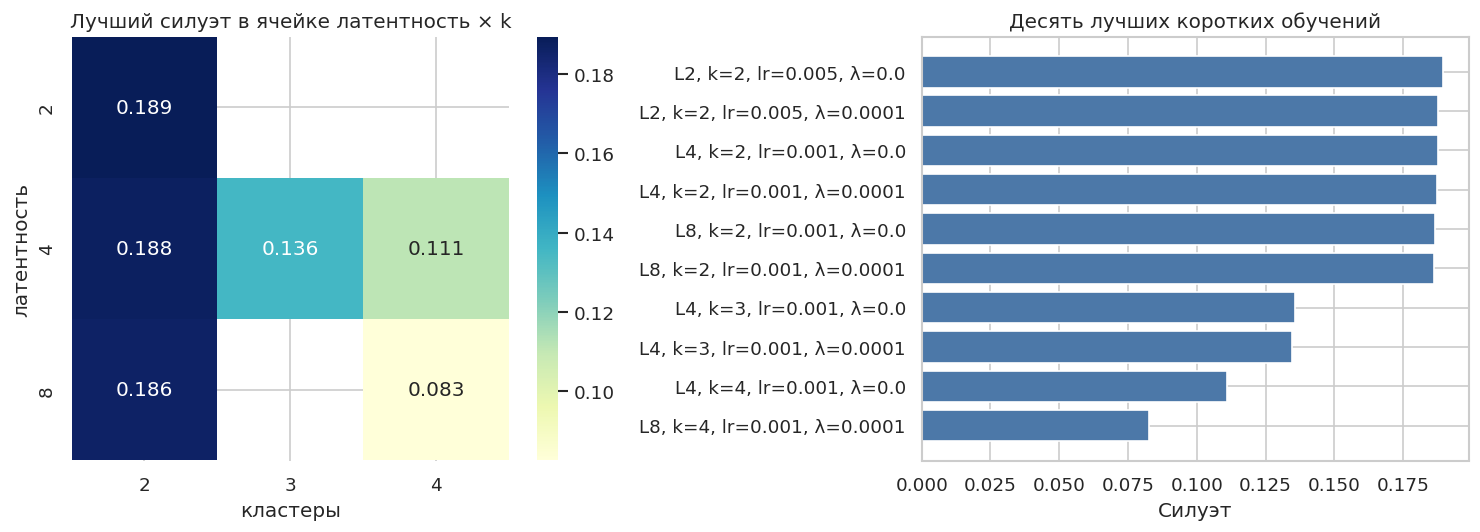

Лучший силуэт: {'латентность': 2, 'кластеры': 2, 'скорость': 0.005, 'L2': 0.0, 'MSE': 0.5898475646972656, 'силуэт': 0.1894073486328125, 'уверенность': 0.8488483428955078, 'годен': True}
Лучшее восстановление MSE: {'латентность': 2, 'кластеры': 2, 'скорость': 0.005, 'L2': 0.0001, 'MSE': 0.5883029699325562, 'силуэт': 0.18786153197288513, 'уверенность': 0.8450942039489746, 'годен': True}
Лучший силуэт и лучшее восстановление не совпали: хорошо восстановить признаки ещё не значит хорошо разделить группы.


In [5]:
grid_rows = []
started = time.time()
configs = [
    (latent_dim, n_clusters, learning_rate, l2)
    for latent_dim in LATENT_GRID
    for n_clusters in CLUSTER_GRID
    for learning_rate in LR_GRID
    for l2 in L2_GRID
]
for index, (latent_dim, n_clusters, learning_rate, l2) in enumerate(configs, start=1):
    trained = fit_vade(
        x_scaled, latent_dim, n_clusters, learning_rate, l2,
        GRID_PRE_EPOCHS, GRID_VADE_EPOCHS, RANDOM_STATE,
    )
    row = {
        "латентность": latent_dim,
        "кластеры": n_clusters,
        "скорость": learning_rate,
        "L2": l2,
    }
    if trained is None or not valid_partition(trained["labels"], n_clusters):
        row.update({"MSE": np.nan, "силуэт": np.nan, "уверенность": np.nan, "годен": False})
        print(f"{index}/{len(configs)} latent={latent_dim}, k={n_clusters}, lr={learning_rate}, l2={l2}: отброшен", flush=True)
    else:
        silhouette = float(silhouette_score(x_scaled, trained["labels"]))
        row.update({
            "MSE": trained["mse"],
            "силуэт": silhouette,
            "уверенность": trained["confidence"],
            "годен": True,
        })
        print(
            f"{index}/{len(configs)} latent={latent_dim}, k={n_clusters}, lr={learning_rate}, l2={l2}: "
            f"силуэт={silhouette:.3f}, MSE={trained['mse']:.3f}",
            flush=True,
        )
    grid_rows.append(row)
    if trained is not None:
        del trained

grid = pd.DataFrame(grid_rows)
grid.to_csv(OUT / "hp_grid.csv", index=False, encoding="utf-8-sig")
print(f"Сетка заняла {(time.time() - started) / 60:.1f} мин.")
display(grid.sort_values("силуэт", ascending=False).round(4))

heat = grid.pivot_table(index="латентность", columns="кластеры", values="силуэт", aggfunc="max")
top = grid.dropna(subset=["силуэт"]).sort_values("силуэт", ascending=False).head(10).iloc[::-1]
top_labels = [
    f"L{int(row['латентность'])}, k={int(row['кластеры'])}, lr={row['скорость']}, λ={row['L2']}"
    for _, row in top.iterrows()
]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
annot = heat.apply(lambda column: column.map(lambda value: "—" if pd.isna(value) else f"{value:.3f}"))
sns.heatmap(heat, annot=annot, fmt="", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Лучший силуэт в ячейке латентность × k")
axes[1].barh(top_labels, top["силуэт"], color="#4C78A8")
axes[1].set_xlabel("Силуэт")
axes[1].set_title("Десять лучших коротких обучений")
fig.tight_layout()
save_fig(fig, "05_giperparametry.png")
plt.show()

best_mse_row = grid.loc[grid["MSE"].idxmin()]
best_sil_row = grid.loc[grid["силуэт"].idxmax()]
same_goal = (
    int(best_mse_row["латентность"]) == int(best_sil_row["латентность"])
    and int(best_mse_row["кластеры"]) == int(best_sil_row["кластеры"])
    and float(best_mse_row["скорость"]) == float(best_sil_row["скорость"])
    and float(best_mse_row["L2"]) == float(best_sil_row["L2"])
)
print("Лучший силуэт:", best_sil_row.to_dict())
print("Лучшее восстановление MSE:", best_mse_row.to_dict())
if same_goal:
    print("Лучший силуэт и лучшее восстановление совпали.")
else:
    print("Лучший силуэт и лучшее восстановление не совпали: хорошо восстановить признаки ещё не значит хорошо разделить группы.")


## 5. Итоговое обучение

Победитель сетки обучается заново и дольше. Если длинный прогон разваливается или схлопывает кластер, берётся следующая строка сетки. Рядом сохраняется разбиение сразу после инициализации GMM: по нему видно, что добавило именно совместное обучение.


Итоговая VaDE: латентность 2, k=2, скорость 0.005, L2 0.0, MSE 0.556, уверенность 0.842
Размеры кластеров: [1448, 3450]


скрин: dop_zadanie/screenshots/06_obuchenie.png


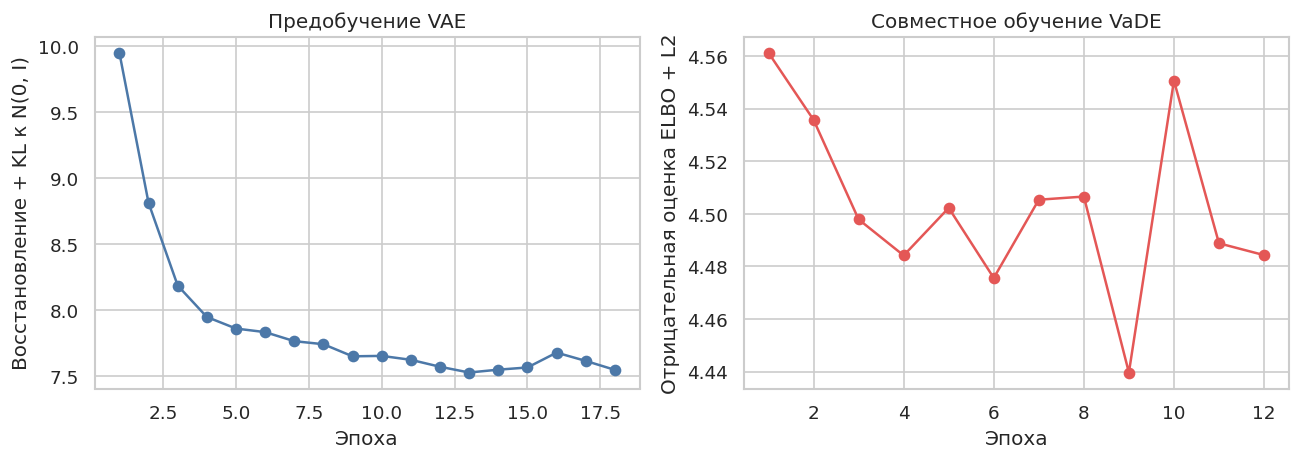

In [6]:
ranked = grid.dropna(subset=["силуэт"]).sort_values("силуэт", ascending=False)
final = None
chosen = None
for _, candidate in ranked.iterrows():
    trained = fit_vade(
        x_scaled,
        int(candidate["латентность"]),
        int(candidate["кластеры"]),
        float(candidate["скорость"]),
        float(candidate["L2"]),
        FINAL_PRE_EPOCHS,
        FINAL_VADE_EPOCHS,
        RANDOM_STATE,
    )
    if trained is None or not valid_partition(trained["labels"], int(candidate["кластеры"])):
        print("Длинное обучение не удержало кластеры, берём следующую строку сетки.", candidate.to_dict())
        continue
    final = trained
    chosen = candidate
    break

if final is None:
    raise RuntimeError("Ни одна конфигурация не дала годного длинного обучения.")

latent_dim = int(chosen["латентность"])
deep_k = int(chosen["кластеры"])
learning_rate = float(chosen["скорость"])
l2 = float(chosen["L2"])
labels = final["labels"]
init_labels = final["init_labels"]
latent = final["latent"]
gamma = final["gamma"]
history = final["history"]
confidence = final["confidence"]
print(
    f"Итоговая VaDE: латентность {latent_dim}, k={deep_k}, "
    f"скорость {learning_rate}, L2 {l2}, MSE {final['mse']:.3f}, уверенность {confidence:.3f}"
)
print("Размеры кластеров:", np.bincount(labels).tolist())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, len(history["pretrain"]) + 1), history["pretrain"], marker="o", color="#4C78A8")
axes[0].set_title("Предобучение VAE")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Восстановление + KL к N(0, I)")
axes[1].plot(range(1, len(history["vade"]) + 1), history["vade"], marker="o", color="#E45756")
axes[1].set_title("Совместное обучение VaDE")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Отрицательная оценка ELBO + L2")
fig.tight_layout()
save_fig(fig, "06_obuchenie.png")
plt.show()


## 6. Сравнение с классическими методами

K-means и EM (Gaussian Mixture с диагональной ковариацией) сами выбирают число кластеров от 2 до 6 по силуэту. DBSCAN число кластеров не задаёт. Перебираются `min_samples` 10, 15 и 20 и радиус `eps` от 0,8 до 2,2. В зачёт идёт только группа не меньше 5% выборки: иначе силуэт раздувают десятки точек вокруг одного облака. Если двух таких групп нет, в таблице у DBSCAN стоит прочерк.

Выше лучше у силуэта, Calinski–Harabasz, ARI, NMI, однородности и полноты. Ниже лучше у Davies–Bouldin. Однородность высокая, когда кластер не смешивает разные оценки. Полнота высокая, когда одна оценка не размазана по многим кластерам.


,k,K-means,GMM
0,2,0.184,0.182
1,3,0.135,0.158
2,4,0.150,0.089
3,5,0.137,0.076
4,6,0.138,0.053


,min_samples,eps,все кластеры,крупные кластеры,крупнейший,второй по размеру,шум после очистки,силуэт
0,10,0.8,7,0,60,16,1.000,NaN
1,10,1.0,25,0,158,58,1.000,NaN
2,10,1.2,20,1,1714,53,0.650,NaN
3,10,1.4,5,1,3306,29,0.325,NaN
4,10,1.6,2,1,4016,8,0.180,NaN
5,10,1.8,2,1,4373,10,0.107,NaN
6,10,2.0,3,1,4570,22,0.067,NaN
7,10,2.2,2,1,4699,33,0.041,NaN
8,15,0.8,1,0,47,0,1.000,NaN
9,15,1.0,11,0,100,37,1.000,NaN


DBSCAN собирает два сгустка только ценой большого шума: 817 и 383 точек, шум 76% при min_samples=15, eps=1.2.


скрин: dop_zadanie/screenshots/07_podbor_k.png


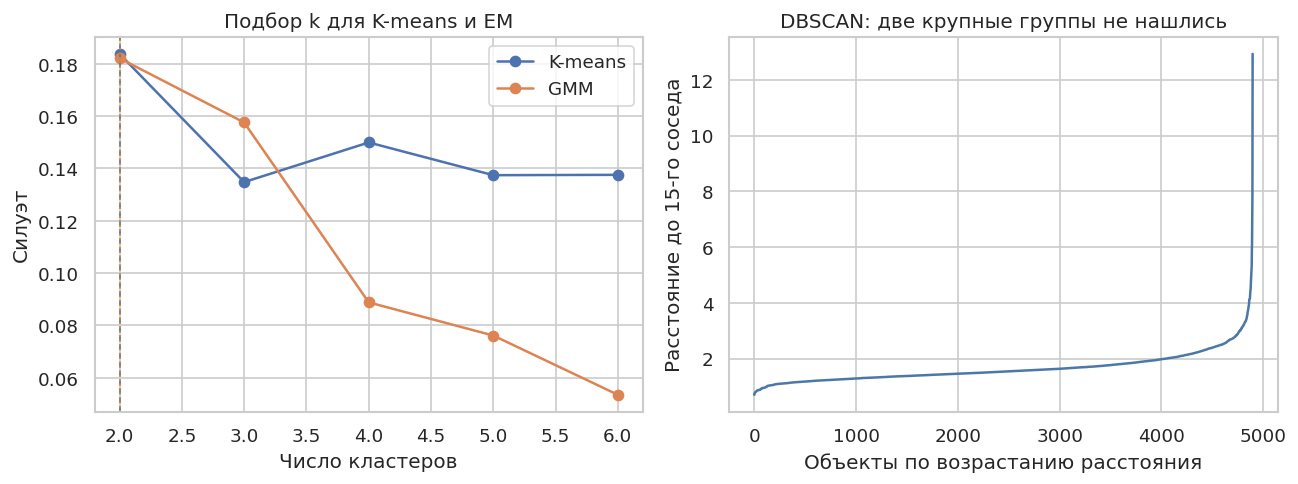

,Модель,k,Силуэт,Davies-Bouldin,Calinski-Harabasz,ARI,NMI,Homogeneity,Completeness,Доля шума
0,K-means (k=2),2,0.184,1.998,1033.340,0.024,0.044,0.034,0.064,0.000
1,"GMM, EM (k=2)",2,0.182,2.032,965.103,0.027,0.053,0.040,0.079,0.000
2,DBSCAN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.755
3,"VAE + GMM, старт (k=2)",2,0.187,1.999,961.489,0.012,0.036,0.027,0.055,0.000
4,VaDE (k=2),2,0.192,1.957,933.848,0.009,0.036,0.027,0.057,0.000


скрин: dop_zadanie/screenshots/08_sravnenie.png


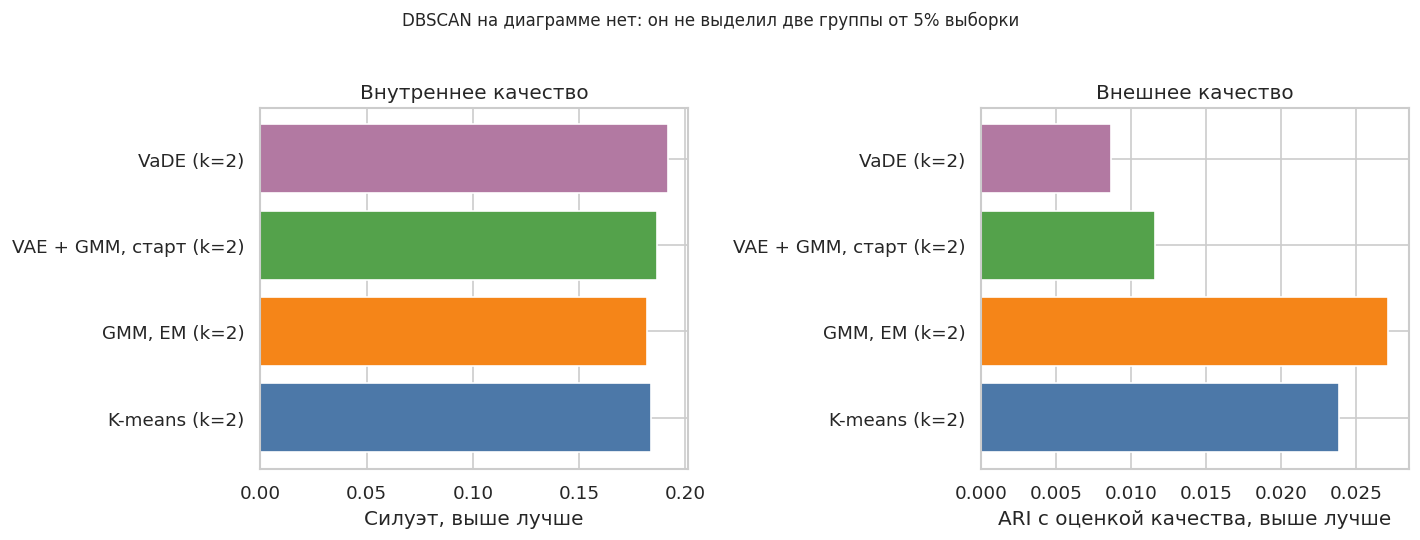

скрин: dop_zadanie/screenshots/09_tablica_metrik.png


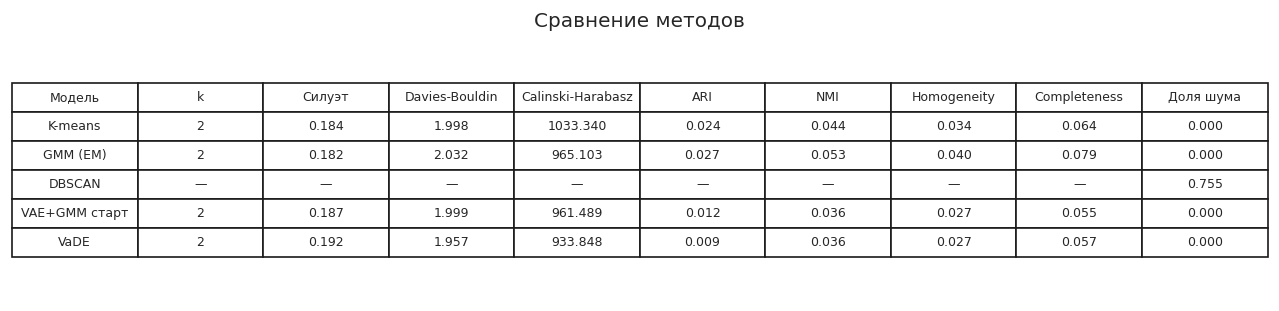

In [7]:
def metric_row(name, labels_pred, noise_ok=False):
    labels_pred = np.asarray(labels_pred)
    mask = np.ones(len(labels_pred), dtype=bool) if not noise_ok else labels_pred >= 0
    used = labels_pred[mask]
    n_clusters = int(len(np.unique(used))) if len(used) else 0
    row = {
        "Модель": name,
        "k": n_clusters,
        "Силуэт": np.nan,
        "Davies-Bouldin": np.nan,
        "Calinski-Harabasz": np.nan,
        "ARI": np.nan,
        "NMI": np.nan,
        "Homogeneity": np.nan,
        "Completeness": np.nan,
        "Доля шума": float((~mask).mean()),
    }
    if mask.sum() > n_clusters >= 2:
        row["Силуэт"] = float(silhouette_score(x_scaled[mask], used))
        row["Davies-Bouldin"] = float(davies_bouldin_score(x_scaled[mask], used))
        row["Calinski-Harabasz"] = float(calinski_harabasz_score(x_scaled[mask], used))
        row["ARI"] = float(adjusted_rand_score(y[mask], used))
        row["NMI"] = float(normalized_mutual_info_score(y[mask], used))
        row["Homogeneity"] = float(homogeneity_score(y[mask], used))
        row["Completeness"] = float(completeness_score(y[mask], used))
    return row

k_rows = []
best_km = {"silhouette": -np.inf}
best_gmm = {"silhouette": -np.inf}
for k in range(2, 7):
    km_labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(x_scaled)
    gmm_labels = GaussianMixture(
        n_components=k, covariance_type="diag", n_init=3, random_state=RANDOM_STATE
    ).fit_predict(x_scaled)
    km_sil = float(silhouette_score(x_scaled, km_labels))
    gmm_sil = float(silhouette_score(x_scaled, gmm_labels))
    k_rows.append({"k": k, "K-means": km_sil, "GMM": gmm_sil})
    if km_sil > best_km["silhouette"]:
        best_km = {"silhouette": km_sil, "k": k, "labels": km_labels}
    if gmm_sil > best_gmm["silhouette"]:
        best_gmm = {"silhouette": gmm_sil, "k": k, "labels": gmm_labels}
k_table = pd.DataFrame(k_rows)
k_table.to_csv(OUT / "k_classical.csv", index=False, encoding="utf-8-sig")
display(k_table.round(3))

min_samples_plot = 15
neighbor_distance = np.sort(
    NearestNeighbors(n_neighbors=min_samples_plot).fit(x_scaled).kneighbors(x_scaled)[0][:, -1]
)
eps_grid = [round(float(value), 3) for value in np.linspace(0.8, 2.2, 8)]
db_rows = []
for min_samples in (10, 15, 20):
    for eps in eps_grid:
        db_labels = DBSCAN(eps=float(eps), min_samples=min_samples).fit_predict(x_scaled)
        counts = np.bincount(db_labels[db_labels >= 0]) if np.any(db_labels >= 0) else np.array([], dtype=int)
        raw_k = int((counts > 0).sum()) if len(counts) else 0
        large_cut = MIN_CLUSTER_SHARE * len(db_labels)
        large_k = int((counts >= large_cut).sum()) if len(counts) else 0
        largest = int(counts.max()) if len(counts) else 0
        second_size = int(np.sort(counts)[-2]) if raw_k >= 2 else 0
        cleaned = db_labels.copy()
        for cluster_id, count in enumerate(counts):
            if count < large_cut:
                cleaned[db_labels == cluster_id] = -1
        cleaned_noise = float(np.mean(cleaned < 0))
        silhouette = np.nan
        if large_k >= 2 and cleaned_noise <= 0.50:
            silhouette = float(silhouette_score(x_scaled[cleaned >= 0], cleaned[cleaned >= 0]))
        db_rows.append({
            "min_samples": min_samples,
            "eps": float(eps),
            "все кластеры": raw_k,
            "крупные кластеры": large_k,
            "крупнейший": largest,
            "второй по размеру": second_size,
            "шум после очистки": cleaned_noise,
            "силуэт": silhouette,
            "labels": cleaned,
        })
db_table = pd.DataFrame([{key: value for key, value in row.items() if key != "labels"} for row in db_rows])
db_table.to_csv(OUT / "dbscan_grid.csv", index=False, encoding="utf-8-sig")
display(db_table.round(3))

separated_rows = [row for row in db_rows if np.isfinite(row["силуэт"])]
large_rows = [row for row in db_rows if row["крупные кластеры"] >= 2]
db_separated = bool(separated_rows)
if db_separated:
    best_db = max(separated_rows, key=lambda row: row["силуэт"])
    print(
        f"DBSCAN: две крупные группы нашлись при min_samples={best_db['min_samples']}, "
        f"eps={best_db['eps']}, силуэт={best_db['силуэт']:.3f}."
    )
elif large_rows:
    best_db = min(large_rows, key=lambda row: row["шум после очистки"])
    print(
        "DBSCAN собирает два сгустка только ценой большого шума: "
        f"{best_db['крупнейший']} и {best_db['второй по размеру']} точек, "
        f"шум {best_db['шум после очистки']:.0%} "
        f"при min_samples={best_db['min_samples']}, eps={best_db['eps']}."
    )
else:
    best_db = max(db_rows, key=lambda row: (row["второй по размеру"], -row["шум после очистки"]))
    print(
        "DBSCAN не собрал двух групп размером хотя бы 5% выборки. "
        f"Самый большой второй сгусток: {best_db['второй по размеру']} точек "
        f"при min_samples={best_db['min_samples']}, eps={best_db['eps']}."
    )

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(k_table["k"], k_table["K-means"], marker="o", label="K-means")
axes[0].plot(k_table["k"], k_table["GMM"], marker="o", label="GMM")
axes[0].axvline(best_km["k"], color="#4C78A8", ls="--", lw=1)
axes[0].axvline(best_gmm["k"], color="#F58518", ls=":", lw=1)
axes[0].set_xlabel("Число кластеров")
axes[0].set_ylabel("Силуэт")
axes[0].set_title("Подбор k для K-means и EM")
axes[0].legend()
axes[1].plot(neighbor_distance, color="#4C78A8")
if db_separated:
    axes[1].axhline(best_db["eps"], color="#E45756", ls="--", label=f"eps = {best_db['eps']}")
    axes[1].legend()
    axes[1].set_title("Подбор eps для DBSCAN")
else:
    axes[1].set_title("DBSCAN: две крупные группы не нашлись")
axes[1].set_xlabel("Объекты по возрастанию расстояния")
axes[1].set_ylabel(f"Расстояние до {min_samples_plot}-го соседа")
fig.tight_layout()
save_fig(fig, "07_podbor_k.png")
plt.show()

if db_separated:
    db_metric = metric_row(
        f"DBSCAN (eps={best_db['eps']})", best_db["labels"], noise_ok=True
    )
else:
    db_metric = {
        "Модель": "DBSCAN",
        "k": 0,
        "Силуэт": np.nan,
        "Davies-Bouldin": np.nan,
        "Calinski-Harabasz": np.nan,
        "ARI": np.nan,
        "NMI": np.nan,
        "Homogeneity": np.nan,
        "Completeness": np.nan,
        "Доля шума": float(best_db["шум после очистки"]),
    }
metrics = pd.DataFrame([
    metric_row(f"K-means (k={best_km['k']})", best_km["labels"]),
    metric_row(f"GMM, EM (k={best_gmm['k']})", best_gmm["labels"]),
    db_metric,
    metric_row(f"VAE + GMM, старт (k={deep_k})", init_labels),
    metric_row(f"VaDE (k={deep_k})", labels),
])
metrics.to_csv(OUT / "metrics_comparison.csv", index=False, encoding="utf-8-sig")
display(metrics.round(3))

plot_metrics = metrics.dropna(subset=["Силуэт"]).reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
names = plot_metrics["Модель"].tolist()
colors = ["#4C78A8", "#F58518", "#54A24B", "#B279A2", "#E45756"]
bar_colors = colors[:len(names)]
axes[0].barh(names, plot_metrics["Силуэт"], color=bar_colors)
axes[0].set_xlabel("Силуэт, выше лучше")
axes[0].set_title("Внутреннее качество")
axes[1].barh(names, plot_metrics["ARI"], color=bar_colors)
axes[1].set_xlabel("ARI с оценкой качества, выше лучше")
axes[1].set_title("Внешнее качество")
if not db_separated:
    fig.suptitle("DBSCAN на диаграмме нет: он не выделил две группы от 5% выборки", y=1.02, fontsize=10)
fig.tight_layout()
save_fig(fig, "08_sravnenie.png")
plt.show()

short = metrics.copy()
short["Модель"] = [
    "K-means",
    "GMM (EM)",
    "DBSCAN",
    "VAE+GMM старт",
    "VaDE",
]
show_cols = ["Модель", "k", "Силуэт", "Davies-Bouldin", "Calinski-Harabasz", "ARI", "NMI", "Homogeneity", "Completeness", "Доля шума"]
shown_metrics = short[show_cols]

def metric_cell(column, value):
    if column == "Модель":
        return str(value)
    if pd.isna(value):
        return "—"
    if column == "k":
        return "—" if int(value) == 0 else str(int(value))
    return f"{float(value):.3f}"

cell_values = [
    [metric_cell(column, row[column]) for column in show_cols]
    for _, row in shown_metrics.iterrows()
]
fig, ax = plt.subplots(figsize=(13.5, 2.8))
ax.axis("off")
ax.set_title("Сравнение методов", pad=8)
metric_table = ax.table(cellText=cell_values, colLabels=show_cols, loc="center", cellLoc="center")
metric_table.auto_set_font_size(False)
metric_table.set_fontsize(7.5)
metric_table.scale(1, 1.45)
save_fig(fig, "09_tablica_metrik.png")
plt.show()


## 7. Латентное пространство

t-SNE строится по латентным средним, на случайной тысяче двух тысяч точек. Метрики выше посчитаны на всей выборке, картинка только показывает форму. Если победившая размерность равна 2, рядом оставлена сама латентная плоскость: t-SNE её не подменяет.


Силуэт на плоскости t-SNE, подвыборка 2000: 0.374


скрин: dop_zadanie/screenshots/10_tsne.png


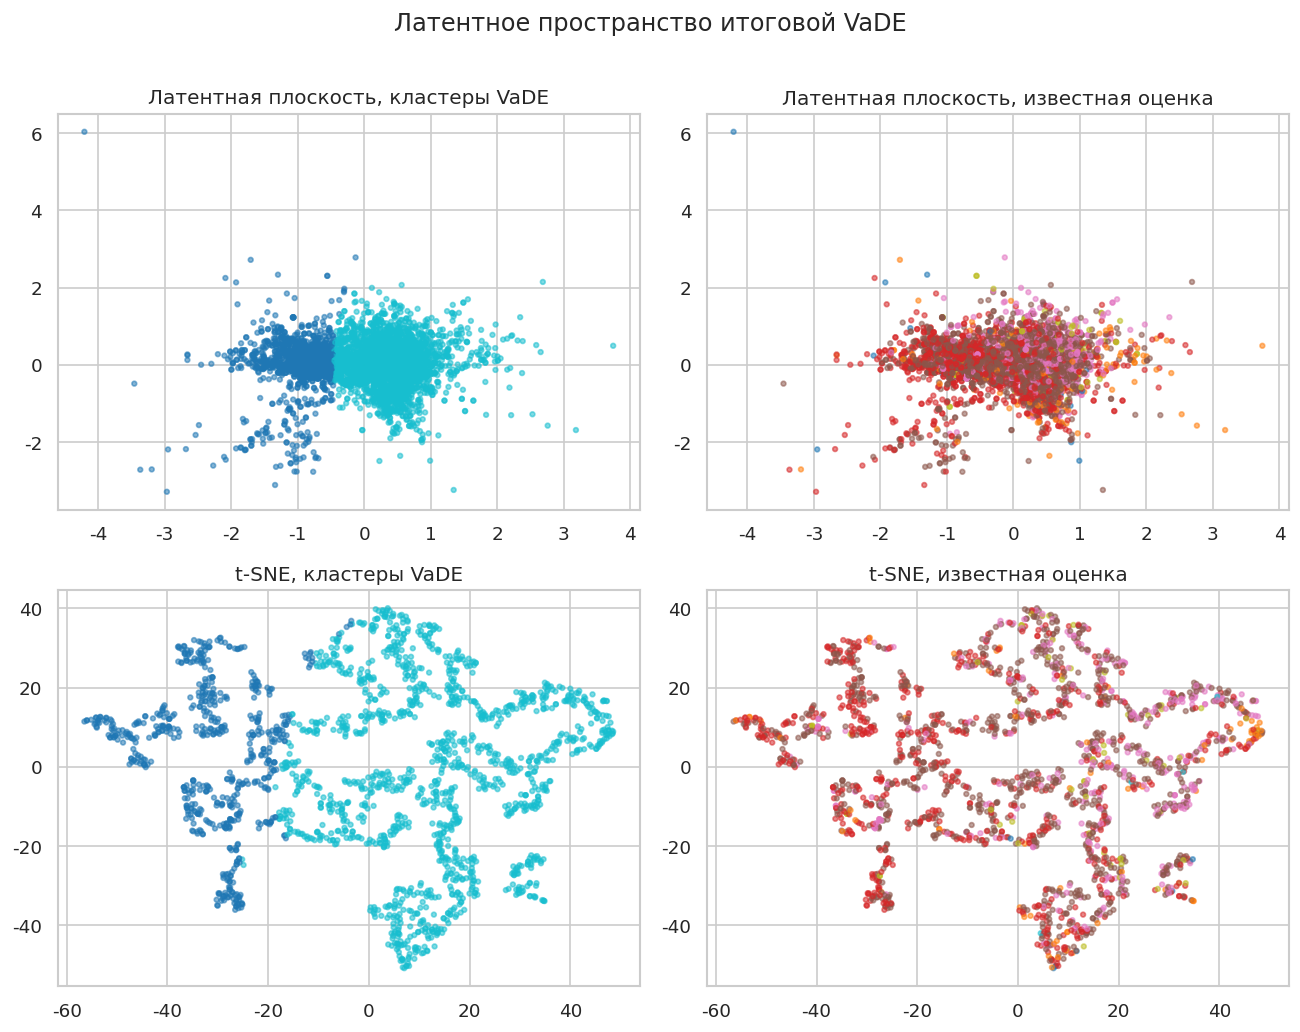

In [8]:
sample_index = np.random.default_rng(RANDOM_STATE).choice(len(latent), size=2000, replace=False)
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=750,
    random_state=RANDOM_STATE,
).fit_transform(latent[sample_index])
visual_silhouette = float(silhouette_score(tsne, labels[sample_index]))
print(f"Силуэт на плоскости t-SNE, подвыборка 2000: {visual_silhouette:.3f}")

if latent_dim == 2:
    fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
    panels = (
        (axes[0, 0], latent[:, 0], latent[:, 1], labels, "Латентная плоскость, кластеры VaDE", np.arange(len(labels))),
        (axes[0, 1], latent[:, 0], latent[:, 1], y, "Латентная плоскость, известная оценка", np.arange(len(labels))),
        (axes[1, 0], tsne[:, 0], tsne[:, 1], labels[sample_index], "t-SNE, кластеры VaDE", sample_index),
        (axes[1, 1], tsne[:, 0], tsne[:, 1], y[sample_index], "t-SNE, известная оценка", sample_index),
    )
    for axis, xs, ys, color, title, _ in panels:
        axis.scatter(xs, ys, c=color, cmap="tab10", s=8, alpha=0.55)
        axis.set_title(title)
    fig.suptitle("Латентное пространство итоговой VaDE", y=1.01)
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    axes[0].scatter(tsne[:, 0], tsne[:, 1], c=labels[sample_index], cmap="tab10", s=10, alpha=0.7)
    axes[0].set_title("t-SNE, кластеры VaDE")
    axes[1].scatter(tsne[:, 0], tsne[:, 1], c=y[sample_index], cmap="viridis", s=10, alpha=0.7)
    axes[1].set_title("t-SNE, известная оценка")
    for axis in axes:
        axis.set_xlabel("t-SNE 1")
        axis.set_ylabel("t-SNE 2")
    fig.suptitle(f"t-SNE латентного пространства, размерность {latent_dim}", y=1.02)
fig.tight_layout()
save_fig(fig, "10_tsne.png")
plt.show()


## 8. Интерпретация групп и устойчивость

Профиль кластера — средние исходных признаков и самая частая оценка. Устойчивость проверяется двумя способами. Первый: три полных обучения победившей настройки с разными датчиками, согласие меток по ARI. Второй: восемь подвыборок по 80% уже полученного латентного пространства, на каждой заново запускается GMM. Первое отвечает на вопрос, повторяет ли сеть разбиение. Второе — не держится ли оно на нескольких точках.


,объектов,Фиксированная кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный диоксид серы,Общий диоксид серы,pH,Сульфаты,Спирт,частая оценка,доля частой оценки
кластер,,,,,,,,,,,,,
0,1448,6.948,0.280,0.379,11.404,0.058,48.799,176.956,3.137,0.499,9.407,5,0.454
1,3450,6.816,0.277,0.316,4.287,0.041,29.646,122.162,3.210,0.486,10.979,6,0.459


скрин: dop_zadanie/screenshots/11_profili.png


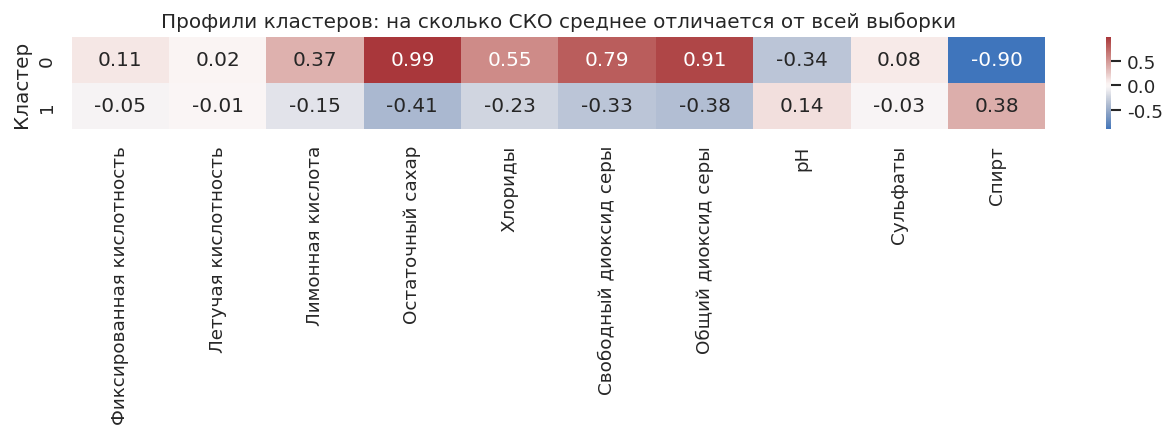

скрин: dop_zadanie/screenshots/12_ocenki.png


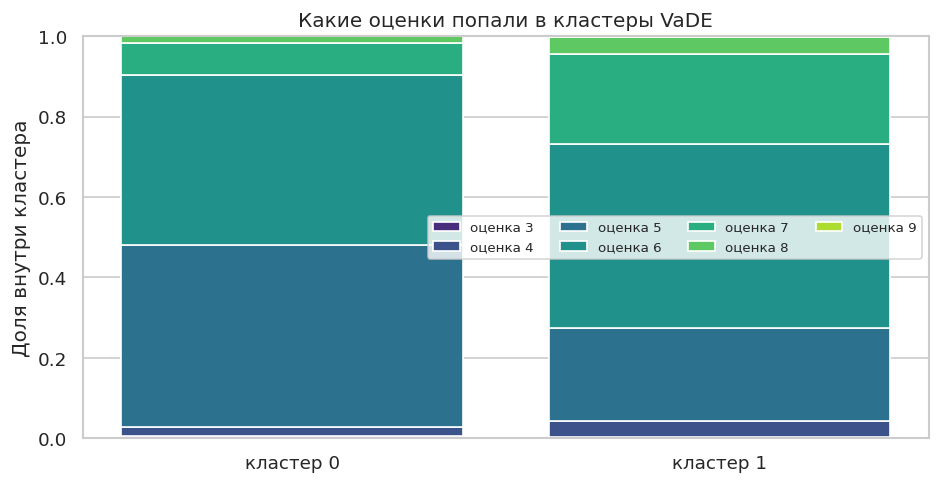

Повторное обучение, датчик 7


Повторное обучение, датчик 99


Датчик 99 не дал годного разбиения.


,сравнение,ARI
0,42 и 7,0.846


ARI бутстрепа GMM: [0.823, 0.821, 0.831, 0.852, 0.847, 0.809, 0.842, 0.833]


скрин:

 dop_zadanie/screenshots/13_ustoychivost.png


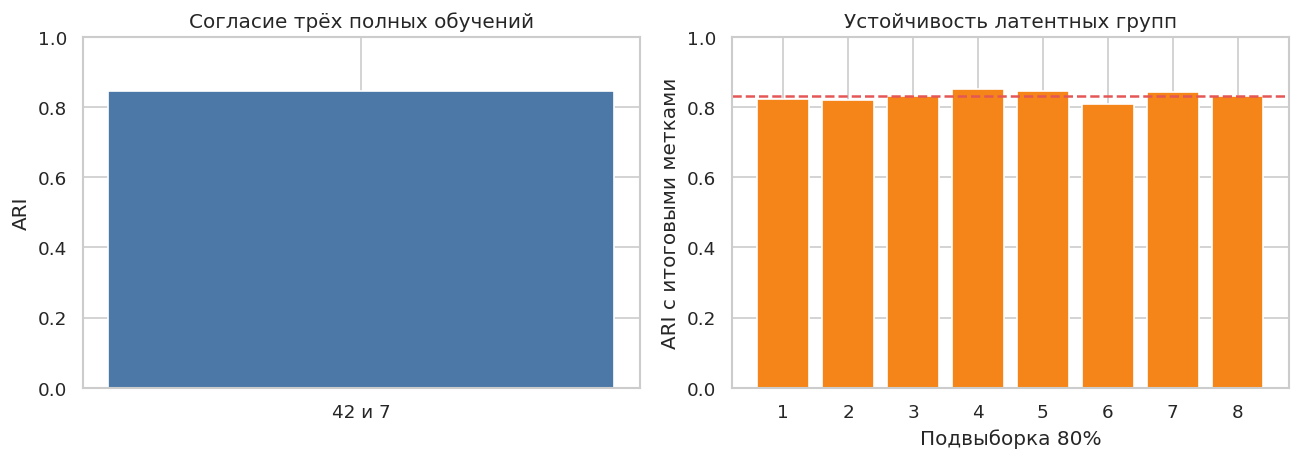

## Интерпретация и вывод

Итоговая VaDE: латентность 2, 2 кластера, скорость 0,005, L2 0. Настройка выбрана по силуэту короткой сетки, без подглядывания в оценку. Длинное обучение: 18 эпох предобучения и 12 эпох совместного ELBO. Средняя уверенность назначения 0,842.
Мягкие назначения уверенные: у типичной точки одна компонента смеси заметно вероятнее остальных.

Силуэт VaDE 0,192, Davies–Bouldin 1,957, Calinski–Harabasz 933,8. Лучший классический метод по силуэту — K-means (k=2) (0,184). Выигрыш VaDE по силуэту маленький. На десяти числовых признаках глубокая модель почти повторяет геометрию, которую уже видят K-means и EM.
Совместное обучение подняло силуэт с 0,187 на старте VAE+GMM до 0,192.

Совпадение с оценкой слабое: ARI у VaDE 0,009, у лучшего по ARI классического метода 0,027. Баллы 5, 6 и 7 химически близки, поэтому кластер собирает соседние оценки, а не один балл.
DBSCAN не делит всю таблицу. Два сгустка крупнее 5% появляются только вместе с большой долей шума: 817 и 383 точек, шум 76% при eps=1,2 и min_samples=15. Стили вина не разделены пустым пространством, поэтому в метрики DBSCAN не поставлен.
Однородность VaDE 0,027, полнота 0,057. Низкая однородность значит, что внутри кластера лежат разные баллы. Низкая полнота значит, что один балл не собран в одном кластере.

Сильнее всего средние кластеров расходятся по признаку «Остаточный сахар».
Кластер 0: 1448 образцов (30%). Чаще всего оценка 5 (45% кластера). Ниже среднего выделяется Спирт (-0,9 СКО), выше среднего — Остаточный сахар (0,99 СКО). Сахар 11,4, спирт 9,41%.
Кластер 1: 3450 образцов (70%). Чаще всего оценка 6 (46% кластера). Ниже среднего выделяется Остаточный сахар (-0,41 СКО), выше среднего — Спирт (0,38 СКО). Сахар 4,29, спирт 10,98%.

На t-SNE группы разделены заметно, визуальная структура поддерживает метрики.
Средний ARI трёх полных обучений 0,846. Полные перезапуски почти повторяют одно и то же разбиение. Средний ARI бутстрепа латентной GMM 0,832. В латентном пространстве группы устойчивы: новая смесь на 80% точек их повторяет.

Итог. Данные для кластеризации пригодны как химическая таблица с двумя-четырьмя стилями, а не как задача восстановить семь оценок. Выигрыш VaDE по силуэту маленький. На десяти числовых признаках глубокая модель почти повторяет геометрию, которую уже видят K-means и EM. Глубокую модель здесь уместно оставить как проверку, а рабочим разбиением считать тот метод, у которого выше силуэт и понятнее профиль по сахару и спирту.

Скрины: `dop_zadanie/screenshots/`. Таблицы: `dop_zadanie/output/`. Основная лабораторная: `lab3_clustering.ipynb`.

Файлы скринов:
dop_zadanie/screenshots/01_opisanie_priznakov.png
dop_zadanie/screenshots/02_raspredeleniya.png
dop_zadanie/screenshots/03_korrelyaciya.png
dop_zadanie/screenshots/04_sahar_i_spirt.png
dop_zadanie/screenshots/05_giperparametry.png
dop_zadanie/screenshots/06_obuchenie.png
dop_zadanie/screenshots/07_podbor_k.png
dop_zadanie/screenshots/08_sravnenie.png
dop_zadanie/screenshots/09_tablica_metrik.png
dop_zadanie/screenshots/10_tsne.png
dop_zadanie/screenshots/11_profili.png
dop_zadanie/screenshots/12_ocenki.png
dop_zadanie/screenshots/13_ustoychivost.png


In [9]:
means = pd.DataFrame(x_scaled, columns=kept).assign(cluster=labels).groupby("cluster").mean()
global_std = raw[kept].std(ddof=0).replace(0, np.nan)
raw_means = raw[kept].groupby(labels).mean()
raw_means.index.name = "кластер"
z_means = (raw_means - raw[kept].mean()) / global_std

profile = raw_means.rename(columns=LABELS).copy()
profile.insert(0, "объектов", pd.Series(labels).value_counts().sort_index())
mode_quality = []
mode_share = []
for cluster in profile.index:
    part = y[labels == cluster]
    values, counts = np.unique(part, return_counts=True)
    mode = int(values[counts.argmax()])
    mode_quality.append(mode)
    mode_share.append(float(counts.max() / len(part)))
profile["частая оценка"] = mode_quality
profile["доля частой оценки"] = mode_share
profile.to_csv(OUT / "cluster_profiles.csv", encoding="utf-8-sig")
display(profile.round(3))

z_show = z_means.rename(columns=LABELS)
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(z_show, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Профили кластеров: на сколько СКО среднее отличается от всей выборки")
ax.set_xlabel("")
ax.set_ylabel("Кластер")
fig.tight_layout()
save_fig(fig, "11_profili.png")
plt.show()

quality_levels = sorted(np.unique(y))
shares = []
for cluster in sorted(np.unique(labels)):
    part = y[labels == cluster]
    shares.append([(part == level).mean() for level in quality_levels])
share_frame = pd.DataFrame(shares, columns=[f"оценка {level}" for level in quality_levels])
share_frame.index = [f"кластер {cluster}" for cluster in sorted(np.unique(labels))]
share_frame.to_csv(OUT / "quality_shares.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8, 4.2))
bottom = np.zeros(len(share_frame))
palette = sns.color_palette("viridis", n_colors=len(quality_levels))
for color, column in zip(palette, share_frame.columns):
    ax.bar(share_frame.index, share_frame[column], bottom=bottom, color=color, label=column)
    bottom += share_frame[column].to_numpy()
ax.set_ylabel("Доля внутри кластера")
ax.set_title("Какие оценки попали в кластеры VaDE")
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
save_fig(fig, "12_ocenki.png")
plt.show()

seed_labels = {RANDOM_STATE: labels}
for seed in (7, 99):
    print(f"Повторное обучение, датчик {seed}", flush=True)
    repeated = fit_vade(
        x_scaled, latent_dim, deep_k, learning_rate, l2,
        FINAL_PRE_EPOCHS, FINAL_VADE_EPOCHS, seed,
    )
    if repeated is None or not valid_partition(repeated["labels"], deep_k):
        print(f"Датчик {seed} не дал годного разбиения.")
        continue
    seed_labels[seed] = repeated["labels"]
    del repeated

seed_pairs = []
for (seed_a, labels_a), (seed_b, labels_b) in combinations(seed_labels.items(), 2):
    score = float(adjusted_rand_score(labels_a, labels_b))
    seed_pairs.append({"сравнение": f"{seed_a} и {seed_b}", "ARI": score})
seed_table = pd.DataFrame(seed_pairs)

rng = np.random.default_rng(RANDOM_STATE)
bootstrap_scores = []
subset_size = int(0.8 * len(latent))
for repeat in range(8):
    subset = rng.choice(len(latent), size=subset_size, replace=False)
    gmm_labels = GaussianMixture(
        n_components=deep_k, covariance_type="diag", n_init=3, random_state=repeat
    ).fit_predict(latent[subset])
    bootstrap_scores.append(float(adjusted_rand_score(labels[subset], gmm_labels)))
stability = pd.DataFrame({
    "повтор": np.arange(1, len(bootstrap_scores) + 1),
    "ARI подвыборки": bootstrap_scores,
})
stability.to_csv(OUT / "stability_bootstrap.csv", index=False, encoding="utf-8-sig")
seed_table.to_csv(OUT / "stability_seeds.csv", index=False, encoding="utf-8-sig")
display(seed_table.round(3))
print("ARI бутстрепа GMM:", [round(score, 3) for score in bootstrap_scores])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar([str(row["сравнение"]) for _, row in seed_table.iterrows()], seed_table["ARI"], color="#4C78A8")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("ARI")
axes[0].set_title("Согласие трёх полных обучений")
axes[1].bar(stability["повтор"], stability["ARI подвыборки"], color="#F58518")
axes[1].axhline(float(np.mean(bootstrap_scores)), color="#E45756", ls="--")
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Подвыборка 80%")
axes[1].set_ylabel("ARI с итоговыми метками")
axes[1].set_title("Устойчивость латентных групп")
fig.tight_layout()
save_fig(fig, "13_ustoychivost.png")
plt.show()

vade_row = metrics.iloc[-1]
start_row = metrics.iloc[-2]
classical = metrics.iloc[:3].dropna(subset=["Силуэт"])
best_classical = classical.loc[classical["Силуэт"].idxmax()]
delta = float(vade_row["Силуэт"] - best_classical["Силуэт"])
if delta > 0.02:
    verdict = (
        "VaDE заметно плотнее собирает группы, чем классические методы. "
        "Нелинейное латентное пространство на этих данных полезно."
    )
elif delta > 0:
    verdict = (
        "Выигрыш VaDE по силуэту маленький. На десяти числовых признаках глубокая модель "
        "почти повторяет геометрию, которую уже видят K-means и EM."
    )
else:
    verdict = (
        "VaDE не обгоняет классические методы по силуэту. Для этой таблицы глубокая кластеризация "
        "не обязательна: признаки уже числовые и их немного, смесь в исходном пространстве справляется не хуже."
    )

if float(vade_row["Силуэт"]) >= float(start_row["Силуэт"]):
    joint_text = (
        f"Совместное обучение подняло силуэт с {num(start_row['Силуэт'])} на старте VAE+GMM "
        f"до {num(vade_row['Силуэт'])}."
    )
else:
    joint_text = (
        f"Совместное обучение силуэт не подняло: на старте VAE+GMM было {num(start_row['Силуэт'])}, "
        f"после ELBO стало {num(vade_row['Силуэт'])}. Смесь на предобученном коде уже держала группы."
    )

spread = z_means.var(axis=0).sort_values(ascending=False)
main_feature = spread.index[0]
stories = []
for cluster in profile.index:
    z_row = z_means.loc[cluster].sort_values()
    low_feature = z_row.index[0]
    high_feature = z_row.index[-1]
    stories.append(
        f"Кластер {cluster}: {int(profile.loc[cluster, 'объектов'])} образцов "
        f"({profile.loc[cluster, 'объектов'] / len(labels):.0%}). "
        f"Чаще всего оценка {int(profile.loc[cluster, 'частая оценка'])} "
        f"({profile.loc[cluster, 'доля частой оценки']:.0%} кластера). "
        f"Ниже среднего выделяется {LABELS[low_feature]} ({num(z_row.iloc[0], 2)} СКО), "
        f"выше среднего — {LABELS[high_feature]} ({num(z_row.iloc[-1], 2)} СКО). "
        f"Сахар {num(raw_means.loc[cluster, 'residual sugar'], 2)}, "
        f"спирт {num(raw_means.loc[cluster, 'alcohol'], 2)}%."
    )

mean_seed = float(seed_table["ARI"].mean()) if len(seed_table) else float("nan")
mean_boot = float(np.mean(bootstrap_scores))
if mean_seed >= 0.75:
    seed_text = "Полные перезапуски почти повторяют одно и то же разбиение."
elif mean_seed >= 0.45:
    seed_text = "Перезапуски узнают те же группы лишь отчасти: границы зависят от датчика."
else:
    seed_text = "Перезапуски расходятся. Итоговое разбиение чувствительно к старту обучения."
if mean_boot >= 0.75:
    boot_text = "В латентном пространстве группы устойчивы: новая смесь на 80% точек их повторяет."
elif mean_boot >= 0.45:
    boot_text = "Латентные группы умеренно устойчивы, края подвыборки их немного сдвигают."
else:
    boot_text = "Латентные группы на подвыборках не держатся, сгустки слабые."

if confidence >= 0.8:
    conf_text = "Мягкие назначения уверенные: у типичной точки одна компонента смеси заметно вероятнее остальных."
elif confidence >= 0.6:
    conf_text = "Назначения умеренные: предпочитаемая компонента есть, но соседняя не отброшена далеко."
else:
    conf_text = "Назначения мягкие, компоненты смеси сильно перекрываются."

if visual_silhouette < 0.15:
    visual_text = "На t-SNE группы почти слипаются, и это согласуется со скромным силуэтом."
elif visual_silhouette < 0.35:
    visual_text = "На t-SNE группы различимы, но границы мягкие. Картинка не обещает более сильного разделения, чем метрики."
else:
    visual_text = "На t-SNE группы разделены заметно, визуальная структура поддерживает метрики."

best_ari = float(classical["ARI"].max())
if max(float(vade_row["ARI"]), best_ari) < 0.15:
    quality_text = (
        f"Совпадение с оценкой слабое: ARI у VaDE {num(vade_row['ARI'])}, "
        f"у лучшего по ARI классического метода {num(best_ari)}. "
        "Баллы 5, 6 и 7 химически близки, поэтому кластер собирает соседние оценки, а не один балл."
    )
else:
    quality_text = (
        f"С оценкой есть заметное согласие: ARI у VaDE {num(vade_row['ARI'])}, "
        f"лучший классический ARI {num(best_ari)}."
    )

paragraphs = [
    "## Интерпретация и вывод",
    "",
    (
        f"Итоговая VaDE: латентность {latent_dim}, {deep_k} кластера, скорость {num(learning_rate, 3)}, "
        f"L2 {num(l2, 4)}. Настройка выбрана по силуэту короткой сетки, без подглядывания в оценку. "
        f"Длинное обучение: {FINAL_PRE_EPOCHS} эпох предобучения и {FINAL_VADE_EPOCHS} эпох совместного ELBO. "
        f"Средняя уверенность назначения {num(confidence)}."
    ),
    conf_text,
    "",
    (
        f"Силуэт VaDE {num(vade_row['Силуэт'])}, Davies–Bouldin {num(vade_row['Davies-Bouldin'])}, "
        f"Calinski–Harabasz {num(vade_row['Calinski-Harabasz'], 1)}. "
        f"Лучший классический метод по силуэту — {best_classical['Модель']} "
        f"({num(best_classical['Силуэт'])}). {verdict}"
    ),
    joint_text,
    "",
    quality_text,
    (
        (
            f"DBSCAN при min_samples={int(best_db['min_samples'])} и eps={num(best_db['eps'], 2)} "
            f"дал крупные группы, силуэт {num(best_db['силуэт'])}."
        )
        if db_separated
        else (
            (
                "DBSCAN не делит всю таблицу. Два сгустка крупнее 5% появляются только вместе с большой долей шума: "
                f"{int(best_db['крупнейший'])} и {int(best_db['второй по размеру'])} точек, "
                f"шум {best_db['шум после очистки']:.0%} "
                f"при eps={num(best_db['eps'], 2)} и min_samples={int(best_db['min_samples'])}. "
                "Стили вина не разделены пустым пространством, поэтому в метрики DBSCAN не поставлен."
            )
            if int(best_db["крупные кластеры"]) >= 2
            else (
                "DBSCAN при min_samples 10, 15 и 20 и eps от 0,8 до 2,2 не собрал двух групп "
                "размером хотя бы 5% выборки. Облако одно, плотностный метод здесь не подходит."
            )
        )
    ),
    (
        f"Однородность VaDE {num(vade_row['Homogeneity'])}, полнота {num(vade_row['Completeness'])}. "
        "Низкая однородность значит, что внутри кластера лежат разные баллы. "
        "Низкая полнота значит, что один балл не собран в одном кластере."
    ),
    "",
    f"Сильнее всего средние кластеров расходятся по признаку «{LABELS[main_feature]}».",
    *stories,
    "",
    visual_text,
    (
        f"Средний ARI трёх полных обучений {num(mean_seed)}. {seed_text} "
        f"Средний ARI бутстрепа латентной GMM {num(mean_boot)}. {boot_text}"
    ),
    "",
    (
        "Итог. Данные для кластеризации пригодны как химическая таблица с двумя-четырьмя стилями, "
        "а не как задача восстановить семь оценок. "
        + verdict
        + " Глубокую модель здесь уместно оставить как проверку, а рабочим разбиением считать тот метод, "
        "у которого выше силуэт и понятнее профиль по сахару и спирту."
    ),
    "",
    "Скрины: `dop_zadanie/screenshots/`. Таблицы: `dop_zadanie/output/`. Основная лабораторная: `lab3_clustering.ipynb`.",
]
conclusion = "\n".join(paragraphs)
(OUT / "zaklyuchenie.md").write_text(conclusion, encoding="utf-8")
display(Markdown(conclusion))
print("Файлы скринов:")
for path in sorted(SHOTS.glob("*.png")):
    print(path.relative_to(PROJECT).as_posix())


## Список источников

1. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining from physicochemical properties // Decision Support Systems. 2009.
2. Wine Quality // UCI Machine Learning Repository. URL: https://archive.ics.uci.edu/dataset/186/wine+quality
3. Jiang Z., Zheng Y., Tan H., Tang B., Zhou H. Variational Deep Embedding: An Unsupervised and Generative Approach to Clustering // IJCAI. 2017.
4. Xie J., Girshick R., Farhadi A. Unsupervised Deep Embedding for Clustering Analysis // ICML. 2016.
5. Документация scikit-learn: K-means, Gaussian mixture, DBSCAN, метрики кластеризации. URL: https://scikit-learn.org/stable/modules/clustering.html
6. Документация TensorFlow Keras. URL: https://www.tensorflow.org/guide/keras

## Где лежит дополнительное задание

- `dop_zadanie/dop_zadanie.ipynb` — этот отчёт, с кодом, таблицами и рисунками.
- `dop_zadanie/screenshots/` — скрины по шагам: описание, распределения, корреляция, сахар и спирт, сетка гиперпараметров, кривые обучения, подбор k, сравнение, t-SNE, профили, оценки, устойчивость.
- `dop_zadanie/output/` — те же числа в CSV и текст вывода `zaklyuchenie.md`.
- `lab3_clustering.ipynb` — основная лабораторная №3, её этот ноутбук не заменяет.
